# 03 · Mention labels and coder agreement

Every mention has a **type** (organic / promo / spam / unclear) and a **sentiment** (positive / neutral / negative) from three independent Haiku coders. Where they disagreed, a Sonnet adjudicator decided without seeing their labels. Definitions: `docs/en/codebook.md`. Helpers: `src/label_utils.py`.

This is an AI instrument (machine-machine agreement), not a human gold standard: kappa measures consistency, not correctness.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu
import label_utils as lu

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 90)

In [2]:
d = lu.load(ROOT)
print(f"{len(d):,} labelled mentions")

12,500 labelled mentions


## 0 · First rows

In [3]:
d[lu.LABEL_COLS].head(8)

,platform,brand,type,type_A,type_B,type_C,type_judge,sentiment,sent_A,sent_B,sent_C,sent_judge,type_source
0,twitter,Samsung,spam,spam,spam,spam,,neutral,neutral,neutral,neutral,,haiku_unanimous
1,twitter,Samsung,organic,organic,organic,organic,,positive,positive,positive,positive,,haiku_unanimous
2,twitter,Samsung,organic,organic,organic,organic,,neutral,neutral,neutral,neutral,,haiku_unanimous
3,twitter,Samsung,spam,spam,spam,spam,,neutral,neutral,neutral,neutral,,haiku_unanimous
4,twitter,Samsung,organic,organic,organic,organic,organic,negative,neutral,neutral,negative,negative,haiku_unanimous
5,twitter,Citizens Bank,organic,organic,spam,organic,organic,neutral,neutral,neutral,neutral,neutral,sonnet_adjudicated
6,twitter,Citizens Bank,promo,promo,promo,promo,,neutral,neutral,neutral,neutral,,haiku_unanimous
7,twitter,Citizens Bank,organic,organic,organic,organic,,neutral,neutral,neutral,neutral,,haiku_unanimous


## 1 · Final labels

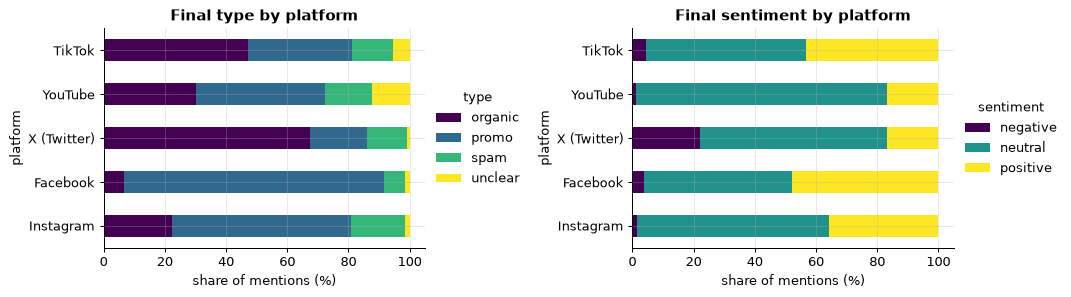

type,organic,promo,spam,unclear,TOTAL
platform,,,,,
tiktok,1181,849,332,138,2500
youtube,753,1058,382,307,2500
twitter,1688,463,327,22,2500
facebook,168,2118,178,36,2500
instagram,558,1466,434,42,2500
TOTAL,4348,5954,1653,545,12500


In [4]:
counts = lu.distribution(d)
counts['type']

In [5]:
counts['sentiment']

sentiment,negative,neutral,positive,TOTAL
platform,,,,
tiktok,108,1311,1081,2500
youtube,32,2045,423,2500
twitter,554,1529,417,2500
facebook,94,1213,1193,2500
instagram,38,1567,895,2500
TOTAL,826,7665,4009,12500


## 2 · Agreement between the three coders

In [6]:
lu.agreement(d).round(3)

agreement  kappa  weighted kappa
field     pair                                       
type      AB              0.87   0.79             NaN
          AC              0.85   0.77             NaN
          BC              0.85   0.77             NaN
          all three       0.79   0.78             NaN
sentiment AB              0.87   0.73            0.75
          AC              0.86   0.71            0.72
          BC              0.86   0.73            0.74
          all three       0.79   0.72             NaN

## 3 · Where do coders disagree?

In [7]:
lu.unanimity(d).round(1)

,unanimous type (%),unanimous sentiment (%)
platform,,
TikTok,74.70,77.30
YouTube,64.20,83.90
X (Twitter),87.80,80.50
Facebook,90.00,78.00
Instagram,79.60,77.20
TOTAL,79.20,79.40


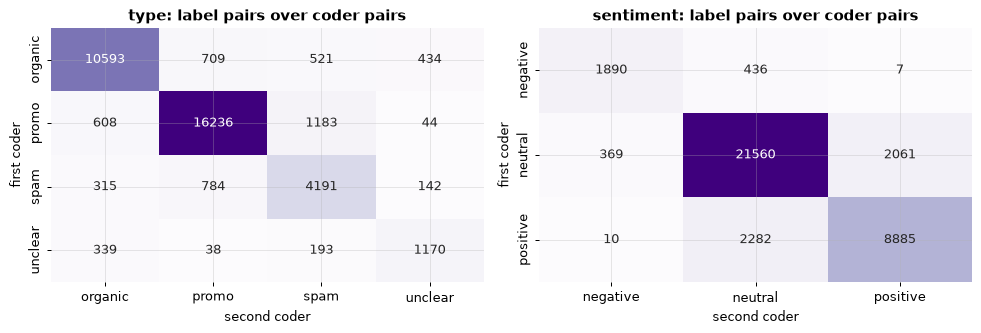

In [8]:
lu.confusions(d)

## 4 · Adjudication: does the judge side with the coders' majority?

In [9]:
lu.adjudication(d)

,type,sentiment
disputed rows,"2,595.00","2,579.00"
with 2-of-3 majority,"2,475.00","2,572.00"
judge sides with majority (%),54.10,55.80
judge = coder A (%),51.30,50.90
judge = coder B (%),47.20,55.20
judge = coder C (%),43.70,48.60


## 5 · Labels and reach (median Brand24 reach by type)

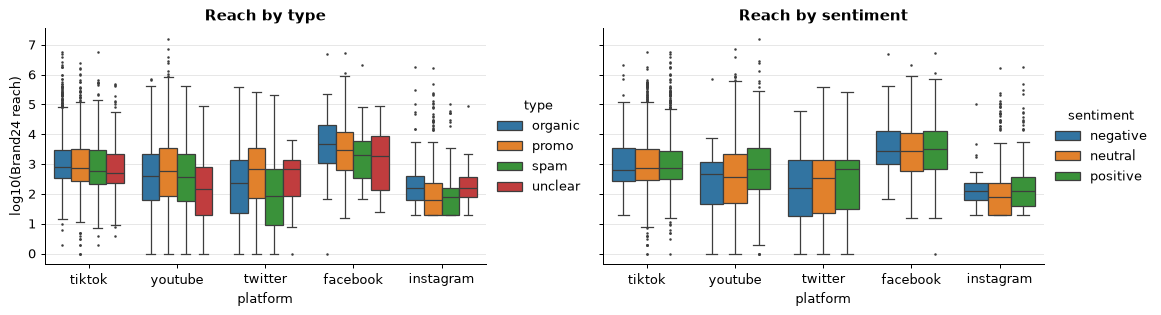

type,organic,promo,spam,unclear
platform,,,,
TikTok,781.00,713.00,601.50,501.50
YouTube,356.00,554.50,364.50,134.00
X (Twitter),134.00,700.00,20.00,700.00
Facebook,"2,000.00","2,447.00",772.00,100.00
Instagram,80.00,20.00,0.00,40.00
TOTAL,366.00,500.00,132.00,232.00


In [10]:
lu.reach_by_label(d)

## Takeaways

- **Agreement is substantial but not perfect.** Pairwise kappa is 0.77–0.79 for type and 0.71–0.73 for sentiment (Fleiss 0.78 / 0.72). All three coders agree on 79% of mentions; 4,668 mentions went to adjudication.
- **Type is the harder, platform-dependent label.** YouTube has the lowest unanimity on type (64%) because of many `unclear` and `promo`/`organic` borderline cases; Facebook and X are the most consistent (88–90%).
- **The adjudicator often overrules the coders' majority.** Where two of three Haiku coders agreed, Sonnet sided with them only about 54–56% of the time. So the disputed rows are genuinely ambiguous, and their final labels are the least reliable part. A sensitivity check (drop adjudicated rows, or use majority vote) should accompany any result that uses these labels.
- **Composition:** 48% promo, 35% organic, 13% spam, 4% unclear; sentiment is mostly neutral (61%), negative is rare (7%). X is the most organic platform, Facebook is dominated by promo.
- **Scope:** this is an AI instrument with no human reference, so kappa shows consistency, not accuracy. A small human check would be the only way to claim validity.